A retrieval call always returns something. It does not tell you whether what it returned is enough to answer the question, and that is the decision that determines whether your agent answers, tries harder, or hands the question to a person.

This recipe adds that decision to a Foundry IQ knowledge base with **Microsoft-Decision-1**, a model that returns typed probabilities instead of text:

- **Foundry IQ** finds evidence. Agentic retrieval plans the query, searches, and returns grounded references.
- **Microsoft-Decision-1** answers one bounded question about that evidence, *is it sufficient?*, as a probability.
- **Your application** owns the policy. The same probability means different things for an internal explanation, a customer reply, and an automated remediation, so the threshold belongs to the use case and not to the model.

You'll build the gate on a fictional SaaS product's support docs with 60 labeled questions, choose a threshold per risk tier by replaying recorded traces offline, escalate through a retrieval-effort cascade, and then expose the policy to a Foundry agent as a function tool. The reusable artifacts are an `EvidenceGate` class and a `policy.json` file.

**The result.** On 40 held-out questions, the `customer_facing` gate with the retry cascade answered 18 and none of them was unsupported (86% coverage, defined in section 9). Always answering was wrong on 51% of the held-out traces.

> **Scope.** This is a *retrieval-sufficiency* gate: it asks whether the retrieved evidence contains what is needed to answer. It does not check whether a generated answer is faithful to that evidence, and, as the model documentation notes, a probability from Decision-1 should not be the sole basis for decisions about people.

## Prerequisites

- A Microsoft Foundry resource with deployments of `Microsoft-Decision-1`, a chat model for the knowledge base planner (this recipe uses `gpt-4.1`), and an embedding model (`text-embedding-3-small`).
- An Azure AI Search service. The knowledge base API used here is in preview (`azure-search-documents` 12.1.0b2 and later).
- The Search service needs the semantic ranker enabled, which agentic retrieval requires.
- Sign in with `az login`, or set API keys. Entra ID is used when a key is not set. With Entra ID you typically need these roles: *Search Service Contributor* and *Search Index Data Contributor* on the Search service, *Cognitive Services OpenAI User* on the Foundry resource for you and for the Search service's managed identity (the vectorizer and planner call it), and *Azure AI User* on the Foundry project for section 13.
- Section 13 needs a Foundry project endpoint. Without one it is skipped and the rest of the notebook still runs.
- Decision-1 deployments are rate limited. The one used here allows 50 requests per minute, and `Decision1.ask` throttles itself to stay under it.

| Variable | Required | Purpose |
|---|---|---|
| `SEARCH_ENDPOINT` | yes | Azure AI Search endpoint |
| `SEARCH_API_KEY` | no | Admin key. Falls back to Entra ID |
| `AOAI_ENDPOINT` | yes | Foundry/Azure OpenAI endpoint used by the vectorizer, KB planner, and embeddings |
| `AOAI_API_KEY` | no | If unset, the search service's managed identity is used for the vectorizer and planner |
| `AOAI_GPT_DEPLOYMENT` | no | KB planner and agent model. Default `gpt-4.1` |
| `AOAI_EMBEDDING_DEPLOYMENT` | no | Default `text-embedding-3-small` |
| `AOAI_EMBEDDING_DIMENSIONS` | no | Default `1536`, matching `text-embedding-3-small` |
| `DECISION_DEPLOYMENT` | no | Default `Decision-1` |
| `DECISION_ENDPOINT` | no | Defaults to `AOAI_ENDPOINT` with `.openai.azure.com` replaced by `.services.ai.azure.com` |
| `DECISION_API_KEY` | no | Defaults to `AOAI_API_KEY`, then Entra ID |
| `FOUNDRY_PROJECT_ENDPOINT` | section 13 | Foundry project endpoint for the agent |
| `COLLECT_TRACES` | no | Set to `1` to re-collect the traces instead of loading the shipped file |

The traces behind sections 8 to 11 are shipped with the recipe, so those sections replay offline and run in seconds. The whole notebook, live sections (4 to 7, 12 and 13) included, took about 3 minutes on the run that produced the outputs below. Section 10 reports the model-token cost of each retrieval strategy; Search service, semantic ranker and embedding charges aren't included in those token counts. Re-collecting the traces takes about 20 minutes, mostly because of the rate limit.

## 1. How the pieces compose

![Architecture: Foundry IQ retrieves evidence, Decision-1 scores sufficiency, the application policy decides whether to answer, retry at higher effort, or escalate](media/foundry-iq-decision-1-gate/01-architecture.png)

Each attempt is two calls: a knowledge base retrieval, then one Decision-1 request that reads the question and the retrieved evidence and returns a probability that the evidence is sufficient. The application compares that probability with the threshold for the current risk tier. Below the threshold it retries at a higher retrieval effort, and when the efforts run out it escalates with a handoff packet.

## 2. Configure and connect

In [1]:
%pip install -q "azure-search-documents==12.1.0b2" "azure-ai-projects>=2.3.0,<2.4.0" azure-identity python-dotenv httpx pandas numpy matplotlib openai

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib, json, os, pathlib, random, re, statistics, threading, time, uuid
from collections import deque
from concurrent.futures import ThreadPoolExecutor

import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv

load_dotenv()


def env(name, *, required=True, default=None):
    value = os.getenv(name, default)
    if required and not value:
        raise RuntimeError(f"Set {name} in your environment or .env file")
    return value


SEARCH_ENDPOINT = env("SEARCH_ENDPOINT")
SEARCH_KEY = env("SEARCH_API_KEY", required=False)
AOAI_ENDPOINT = env("AOAI_ENDPOINT").rstrip("/") + "/"
AOAI_KEY = env("AOAI_API_KEY", required=False)
AOAI_GPT = env("AOAI_GPT_DEPLOYMENT", default="gpt-4.1")
AOAI_EMB = env("AOAI_EMBEDDING_DEPLOYMENT", default="text-embedding-3-small")
EMB_DIMS = int(env("AOAI_EMBEDDING_DIMENSIONS", default="1536"))

DECISION_DEPLOYMENT = env("DECISION_DEPLOYMENT", default="Decision-1")
DECISION_BASE = env(
    "DECISION_ENDPOINT",
    required=False,
    default=AOAI_ENDPOINT.replace(".openai.azure.com", ".services.ai.azure.com"),
).rstrip("/")
DECISION_URL = f"{DECISION_BASE}/providers/microsoft/v1/systemone"
DECISION_KEY = env("DECISION_API_KEY", required=False, default=AOAI_KEY)

COG_SCOPE = "https://cognitiveservices.azure.com/.default"
DATA = pathlib.Path("data/foundry-iq-decision-1-gate/")
MEDIA = pathlib.Path("media/foundry-iq-decision-1-gate/")
K = 3  # evidence documents handed to the gate

print("Search auth      :", "API key" if SEARCH_KEY else "Entra ID")
print("Foundry auth     :", "API key" if AOAI_KEY else "Entra ID / managed identity")
print("Planner model    :", AOAI_GPT)
print("Decision model   :", DECISION_DEPLOYMENT)
print("Evidence per call:", K, "documents")

Search auth      : Entra ID
Foundry auth     : Entra ID / managed identity
Planner model    : gpt-4.1
Decision model   : Decision-1
Evidence per call: 3 documents


## 3. The corpus and the labeled questions

The fictional product is **Relay**, a webhook delivery service. The corpus is 26 short documents of four kinds: guides, runbooks, release notes, and postmortems. They overlap on purpose: a retry fact may appear in a guide and in a release note, and a postmortem may mention a limit that a guide states differently.

The question set has 60 questions in five categories. Each answerable question lists the *evidence sets* that contain its answer, so "did retrieval find enough?" is a lookup, not a judgment call.

| Category | Meaning |
|---|---|
| `single_doc` | One document answers it fully |
| `multi_doc` | The answer needs two documents |
| `partial` | The docs are close but never state the asked detail |
| `near_miss` | The question mentions something that is not in the docs (a plan, a date, a number) |
| `off_corpus` | The question is about something else entirely |

In [3]:
def load_corpus(folder):
    docs = []
    for path in sorted(folder.glob("*.md")):
        _, front, body = path.read_text(encoding="utf-8").split("---\n", 2)
        meta = dict(re.findall(r'^(\w+): "?(.*?)"?$', front, re.M))
        docs.append({
            "id": meta["id"],
            "title": meta["title"],
            "doc_type": meta["doc_type"],
            "api_version": meta["api_versions"],
            "content": f"# {meta['title']}\n\n" + body.strip(),
        })
    return docs


def read_jsonl(path):
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]


docs = load_corpus(DATA / "corpus")
DOCS = {d["id"]: d for d in docs}
questions = read_jsonl(DATA / "questions.jsonl")
QUESTIONS = {q["id"]: q for q in questions}

corpus_summary = (
    pd.DataFrame(docs)
    .assign(words=lambda d: d["content"].str.split().str.len())
    .groupby("doc_type")
    .agg(docs=("id", "count"), avg_words=("words", "mean"))
    .round(0)
    .astype(int)
)
print(corpus_summary.to_string())
print()
print(DOCS["secret-rotation"]["content"][:700], "...")

               docs  avg_words
doc_type                      
guide            11        172
postmortem        6        151
release-notes     4        128
runbook           5        199

# Signing secret rotation

You can rotate an endpoint's signing secret from the console or with `relayctl secrets rotate <endpoint-id>`.

## API v3: grace window

When you rotate on v3, Relay creates a new secret and keeps the old one active for a **grace window**. During the window every delivery is signed with both secrets, so the `Relay-Signature` header contains two `v1` values, newest secret first. When the window ends, the old secret is revoked and the header carries a single `v1` value again.

- **Free and Pro:** the grace window is fixed at **24 hours**.
- **Enterprise:** the grace window is configurable from v3.4 onward. Before v3.4 it was fixed at 24 hours.

To end the window early ...


In [4]:
qdf = pd.DataFrame(questions)
print(pd.crosstab(qdf["category"], qdf["split"], margins=True).to_string())
print()
for category in ["single_doc", "multi_doc", "partial", "near_miss", "off_corpus"]:
    q = qdf[qdf["category"] == category].iloc[0]
    print(f"[{category}] {q['question']}")
    print(f"    gold: {q['gold_answer']}")
    print(f"    evidence sets: {q['evidence_sets'] or 'none (should not be answered)'}\n")

split       dev  test  All
category                  
multi_doc     3     7   10
near_miss     4     6   10
off_corpus    3     7   10
partial       4     6   10
single_doc    6    14   20
All          20    40   60

[single_doc] How many delivery attempts does a webhook get on API v3, and over what period?
    gold: 8 attempts over about 20.6 hours.
    evidence sets: [['delivery-and-retries'], ['release-notes-v3-0']]

[multi_doc] I'm on the Pro plan and just rotated a signing secret on API v3. How long is the old secret still valid, and how should my receiver verify the signature in the meantime?
    gold: The grace window is a fixed 24 hours on Pro. Deliveries carry two v1 values, newest first; the receiver should compare against every v1 value and accept the request if any matches.
    evidence sets: [['secret-rotation', 'signing-and-verification'], ['secret-rotation', 'runbook-signature-failures']]

[partial] Can I set a custom retry schedule for a single endpoint?
    gold: Not s

The `dev` split (20 questions) is used to choose thresholds. The `test` split (40 questions) is used only to report results, so nothing in sections 9 to 11 is tuned on the questions it is measured on.

## 4. Create the Foundry IQ knowledge base

A knowledge base has three layers: an **index** that holds the documents, a **knowledge source** that wraps the index for retrieval, and the **knowledge base** itself, which adds a chat model that plans queries. Names get a random suffix so repeated runs don't collide.

In [5]:
from azure.core.credentials import AzureKeyCredential
from azure.core.exceptions import HttpResponseError
from azure.identity import DefaultAzureCredential, get_bearer_token_provider
from azure.search.documents import SearchClient, SearchIndexingBufferedSender
from azure.search.documents.indexes import SearchIndexClient
from azure.search.documents.indexes.models import (
    AzureOpenAIVectorizer,
    AzureOpenAIVectorizerParameters,
    HnswAlgorithmConfiguration,
    KnowledgeBase,
    KnowledgeBaseAzureOpenAIModel,
    KnowledgeSourceReference,
    SearchField,
    SearchFieldDataType,
    SearchIndex,
    SearchIndexKnowledgeSource,
    SearchIndexKnowledgeSourceParameters,
    SemanticConfiguration,
    SemanticField,
    SemanticPrioritizedFields,
    SemanticSearch,
    SimpleField,
    VectorSearch,
    VectorSearchProfile,
)
from azure.search.documents.knowledgebases import KnowledgeBaseRetrievalClient
from azure.search.documents.knowledgebases.models import (
    KnowledgeBaseMessage,
    KnowledgeBaseMessageTextContent,
    KnowledgeBaseRetrievalRequest,
    KnowledgeRetrievalAutoReasoningEffort,
    KnowledgeRetrievalLowReasoningEffort,
    KnowledgeRetrievalMediumReasoningEffort,
    KnowledgeRetrievalMinimalReasoningEffort,
    KnowledgeRetrievalOutputMode,
    KnowledgeRetrievalSemanticIntent,
    SearchIndexKnowledgeSourceParams,
)
from openai import AzureOpenAI

credential = DefaultAzureCredential()
search_credential = AzureKeyCredential(SEARCH_KEY) if SEARCH_KEY else credential
RUN = uuid.uuid4().hex[:6]
INDEX_NAME, KS_NAME, KB_NAME = f"relay-docs-{RUN}", f"relay-ks-{RUN}", f"relay-kb-{RUN}"

if AOAI_KEY:
    oai = AzureOpenAI(azure_endpoint=AOAI_ENDPOINT, api_key=AOAI_KEY, api_version="2024-10-21")
else:
    oai = AzureOpenAI(
        azure_endpoint=AOAI_ENDPOINT,
        azure_ad_token_provider=get_bearer_token_provider(credential, COG_SCOPE),
        api_version="2024-10-21",
    )

embeddings = oai.embeddings.create(model=AOAI_EMB, input=[d["content"] for d in docs], dimensions=EMB_DIMS).data
rows = [{**d, "content_vector": e.embedding} for d, e in zip(docs, embeddings)]

# api_key=None means the search service's managed identity calls the Foundry resource
model_params = AzureOpenAIVectorizerParameters(
    resource_url=AOAI_ENDPOINT, deployment_name=AOAI_EMB, model_name=AOAI_EMB, api_key=AOAI_KEY
)
index = SearchIndex(
    name=INDEX_NAME,
    fields=[
        SimpleField(name="id", type=SearchFieldDataType.String, key=True, filterable=True),
        SearchField(name="title", type=SearchFieldDataType.String, searchable=True),
        SimpleField(name="doc_type", type=SearchFieldDataType.String, filterable=True, facetable=True),
        SimpleField(name="api_version", type=SearchFieldDataType.String, filterable=True),
        SearchField(name="content", type=SearchFieldDataType.String, searchable=True),
        SearchField(
            name="content_vector",
            type=SearchFieldDataType.Collection(SearchFieldDataType.Single),
            searchable=True,
            vector_search_dimensions=EMB_DIMS,
            vector_search_profile_name="hnsw",
        ),
    ],
    vector_search=VectorSearch(
        profiles=[VectorSearchProfile(name="hnsw", algorithm_configuration_name="alg", vectorizer_name="vec")],
        algorithms=[HnswAlgorithmConfiguration(name="alg")],
        vectorizers=[AzureOpenAIVectorizer(vectorizer_name="vec", parameters=model_params)],
    ),
    semantic_search=SemanticSearch(
        default_configuration_name="sem",
        configurations=[
            SemanticConfiguration(
                name="sem",
                prioritized_fields=SemanticPrioritizedFields(
                    title_field=SemanticField(field_name="title"),
                    content_fields=[SemanticField(field_name="content")],
                ),
            )
        ],
    ),
)

index_client = SearchIndexClient(SEARCH_ENDPOINT, search_credential)
index_client.create_or_update_index(index)
with SearchIndexingBufferedSender(SEARCH_ENDPOINT, INDEX_NAME, search_credential) as sender:
    sender.upload_documents(rows)

search_client = SearchClient(SEARCH_ENDPOINT, INDEX_NAME, search_credential)
for _ in range(30):
    if search_client.get_document_count() >= len(rows):
        break
    time.sleep(2)

index_client.create_or_update_knowledge_source(
    SearchIndexKnowledgeSource(
        name=KS_NAME,
        description="Relay docs, runbooks, release notes, and postmortems.",
        search_index_parameters=SearchIndexKnowledgeSourceParameters(
            search_index_name=INDEX_NAME,
            semantic_configuration_name="sem",
            source_data_fields=[{"name": "id"}, {"name": "title"}, {"name": "doc_type"}, {"name": "content"}],
        ),
    )
)
index_client.create_or_update_knowledge_base(
    KnowledgeBase(
        name=KB_NAME,
        description="Relay support knowledge base",
        models=[
            KnowledgeBaseAzureOpenAIModel(
                azure_open_ai_parameters=AzureOpenAIVectorizerParameters(
                    resource_url=AOAI_ENDPOINT, deployment_name=AOAI_GPT, model_name=AOAI_GPT, api_key=AOAI_KEY
                )
            )
        ],
        knowledge_sources=[KnowledgeSourceReference(name=KS_NAME)],
    )
)
print(f"Indexed {search_client.get_document_count()} documents")
print("Created:", INDEX_NAME, KS_NAME, KB_NAME, sep="\n  ")

Indexed 26 documents
Created:
  relay-docs-a9371c
  relay-ks-a9371c
  relay-kb-a9371c


### Retrieve at a chosen effort

`retrieve_at` wraps one retrieval and returns only what the rest of the recipe needs: the document ids and reranker scores, the evidence text, latency, and what the planner spent. Three details matter in practice:

- **`max_output_documents=K`** caps the evidence. Without a cap this knowledge base returns many more documents than a prompt needs (the probe below prints the count at each effort). That makes "the right document is somewhere in the results" easy to satisfy and gives the gate little to decide.
- **`minimal` takes explicit `intents`** and does no LLM planning. `low`, `medium`, and `auto` take chat `messages`.
- **Partial results are errors.** A knowledge base can return HTTP 206 when a source fails, so the call raises on 206 and on any activity error and retries only transient failures.

In [6]:
EFFORTS = {
    "minimal": KnowledgeRetrievalMinimalReasoningEffort,
    "low": KnowledgeRetrievalLowReasoningEffort,
    "medium": KnowledgeRetrievalMediumReasoningEffort,
    "auto": KnowledgeRetrievalAutoReasoningEffort,
}
kb_client = KnowledgeBaseRetrievalClient(
    endpoint=SEARCH_ENDPOINT, knowledge_base_name=KB_NAME, credential=search_credential
)


class IncompleteRetrieval(RuntimeError):
    pass


def require_complete(pipeline_response, result, _headers):
    if pipeline_response.http_response.status_code == 206:
        raise IncompleteRetrieval("knowledge base returned a partial response (HTTP 206)")
    for activity in result.activity or []:
        if activity.as_dict().get("error"):
            raise IncompleteRetrieval(f"activity error: {activity.as_dict()['error']}")
    return result


def summarize_activity(activity):
    out = {"planner_in": 0, "planner_out": 0, "reasoning_tokens": 0, "queries": []}
    for item in activity or []:
        a = item.as_dict()
        if a["type"] == "modelQueryPlanning":
            out["planner_in"] += a.get("inputTokens", 0)
            out["planner_out"] += a.get("outputTokens", 0)
        elif a["type"] == "agenticReasoning":
            out["reasoning_tokens"] += a.get("reasoningTokens", 0)
        elif a["type"] == "searchIndex":
            query = (a.get("searchIndexArguments") or {}).get("search")
            if query:
                out["queries"].append(query)
    return out


def retrieve_at(question, effort, k=K, attempts=5):
    if effort == "minimal":
        inputs = {"intents": [KnowledgeRetrievalSemanticIntent(search=question)]}
    else:
        inputs = {"messages": [KnowledgeBaseMessage(role="user", content=[KnowledgeBaseMessageTextContent(text=question)])]}
    cap = {} if k is None else {"max_output_documents": k}
    request = KnowledgeBaseRetrievalRequest(
        knowledge_source_params=[
            SearchIndexKnowledgeSourceParams(
                knowledge_source_name=KS_NAME,
                include_references=True,
                include_reference_source_data=True,
                always_query_source=True,
                fail_on_error=True,
            )
        ],
        retrieval_reasoning_effort=EFFORTS[effort](),
        output_mode=KnowledgeRetrievalOutputMode.EXTRACTIVE_DATA,
        include_activity=True,
        **cap,
        **inputs,
    )
    for attempt in range(attempts):
        try:
            started = time.perf_counter()
            result = kb_client.retrieve(request, cls=require_complete)
            elapsed_ms = (time.perf_counter() - started) * 1000
            break
        except (HttpResponseError, IncompleteRetrieval) as exc:
            status = getattr(exc, "status_code", None)
            transient = isinstance(exc, IncompleteRetrieval) or status in (408, 429, 500, 502, 503, 504)
            if not transient or attempt == attempts - 1:
                raise
            time.sleep(min(30, 2**attempt + random.random()))
    refs = result.references or []
    return {
        "effort": effort,
        "doc_ids": [r.source_data["id"] for r in refs],
        "reranker": [r.reranker_score for r in refs],
        "docs": [r.source_data for r in refs],
        "kb_ms": round(elapsed_ms),
        "retries": attempt,
        **summarize_activity(result.activity),
    }


probe = "I'm on the Pro plan and just rotated a signing secret on API v3. How long is the old secret still valid?"
print(probe, "\n")
for effort in EFFORTS:
    ev = retrieve_at(probe, effort)
    print(
        f"{effort:8s} {ev['kb_ms']/1000:5.1f}s  planner tokens in/out {ev['planner_in']}/{ev['planner_out']}  "
        f"docs {ev['doc_ids']}"
    )
    print(f"{'':8s} subqueries: {ev['queries']}")

print("\nThe same probe with no cap on the evidence:")
for effort in EFFORTS:
    print(f"{effort:8s} {len(retrieve_at(probe, effort, k=None)['doc_ids'])} documents")

I'm on the Pro plan and just rotated a signing secret on API v3. How long is the old secret still valid? 



minimal    3.4s  planner tokens in/out 0/0  docs ['release-notes-v3-0', 'secret-rotation', 'mutual-tls']
         subqueries: ["I'm on the Pro plan and just rotated a signing secret on API v3. How long is the old secret still valid?"]


low        3.0s  planner tokens in/out 888/50  docs ['secret-rotation', 'runbook-signature-failures', 'release-notes-v2-9']
         subqueries: ['Pro plan API v3 signing secret validity after rotation', 'API v3 signing secret rotation grace period', 'Pro plan signing secret old secret validity duration after rotation']


medium     5.2s  planner tokens in/out 2860/80  docs ['secret-rotation', 'release-notes-v3-0', 'runbook-signature-failures']
         subqueries: ['Pro plan API v3 signing secret validity after rotation', 'API v3 signing secret rotation grace period', 'How long does old signing secret remain valid after rotation on Pro plan', 'API v3 signing secret expiration policy post-rotation', 'Signing secret overlap period after rotation API v3']


auto       0.6s  planner tokens in/out 0/0  docs ['release-notes-v3-0', 'secret-rotation', 'mutual-tls']
         subqueries: ["I'm on the Pro plan and just rotated a signing secret on API v3. How long is the old secret still valid?"]

The same probe with no cap on the evidence:


minimal  10 documents


low      9 documents


medium   9 documents


auto     10 documents


## 5. Score sufficiency with Decision-1

Decision-1 takes a `state` and one or more typed `questions`. For a gate the right type is `noul`: a yes/no question that returns the probability that the *true* criterion holds. The state is the user's question plus the retrieved evidence, serialized as JSON. The question and its two criteria are fixed text, so the only thing that changes between calls is the state.

`Decision1.ask` adds the two things a loop needs: a rolling rate limiter (the deployment used here allows 50 requests per minute) and a retry on 429 and 5xx.

In [7]:
class Decision1:
    def __init__(self, url, deployment, credential, api_key=None, requests_per_minute=45):
        self.url, self.deployment, self.credential, self.api_key = url, deployment, credential, api_key
        self.http = httpx.Client(timeout=120)
        self.rpm, self.sent, self.lock = requests_per_minute, deque(), threading.Lock()
        self._token = None

    def _headers(self):
        if self.api_key:
            return {"api-key": self.api_key}
        if self._token is None or self._token.expires_on - time.time() < 300:
            self._token = self.credential.get_token(COG_SCOPE)
        return {"Authorization": f"Bearer {self._token.token}"}

    def _throttle(self):
        with self.lock:
            now = time.time()
            while self.sent and now - self.sent[0] > 60:
                self.sent.popleft()
            if len(self.sent) >= self.rpm:
                time.sleep(max(0, 60 - (now - self.sent[0])) + 0.05)
            self.sent.append(time.time())

    def ask(self, state, questions, attempts=6):
        body = {"model": self.deployment, "state": state, "questions": questions}
        for attempt in range(attempts):
            self._throttle()
            started = time.perf_counter()
            response = self.http.post(self.url, headers=self._headers(), json=body)
            if response.status_code == 200:
                payload = response.json()
                meta = {
                    "ms": round((time.perf_counter() - started) * 1000),
                    "input_tokens": payload["usage"]["input_tokens"],
                    "output_tokens": payload["usage"]["output_tokens"],
                }
                return payload["answers"], meta
            if response.status_code in (429, 500, 502, 503, 504):
                time.sleep(float(response.headers.get("retry-after", 2 ** (attempt + 1))))
                continue
            response.raise_for_status()
        raise RuntimeError(f"Decision-1 still failing after {attempts} attempts")


decision = Decision1(DECISION_URL, DECISION_DEPLOYMENT, credential, DECISION_KEY)

SUFFICIENT = {
    "type": "noul",
    "instructions": "Does the evidence contain enough information to fully answer the question?",
    "criteria": {
        "true": "The evidence directly answers every part of the question.",
        "false": "A required part of the answer is missing, or the evidence does not apply.",
    },
}


def evidence_state(question, evidence_docs):
    evidence = [{"ref_id": d["id"], "title": d["title"], "text": d["content"]} for d in evidence_docs]
    return json.dumps({"question": question, "evidence": evidence})


def score_sufficiency(question, evidence_docs, spec=SUFFICIENT):
    answers, meta = decision.ask(evidence_state(question, evidence_docs), {"sufficient": spec})
    return answers["sufficient"]["noul"], meta


print(json.dumps({"model": DECISION_DEPLOYMENT, "state": "<question + evidence JSON>", "questions": {"sufficient": SUFFICIENT}}, indent=2))

{
  "model": "Decision-1",
  "state": "<question + evidence JSON>",
  "questions": {
    "sufficient": {
      "type": "noul",
      "instructions": "Does the evidence contain enough information to fully answer the question?",
      "criteria": {
        "true": "The evidence directly answers every part of the question.",
        "false": "A required part of the answer is missing, or the evidence does not apply."
      }
    }
  }
}


Three hand-built cases show the range of probabilities the gate produces. The evidence is picked from the corpus directly, with no retrieval involved: the right document, an unrelated document, and a document that covers only half of a two-part question.

In [8]:
cases = [
    ("sufficient evidence", "q01", ["delivery-and-retries"]),
    ("unrelated evidence", "q01", ["payload-limits"]),
    ("half the question", "q35", ["rate-limits"]),
]
for label, qid, doc_ids in cases:
    q = QUESTIONS[qid]
    p, meta = score_sufficiency(q["question"], [DOCS[i] for i in doc_ids])
    print(f"{label:20s} P(sufficient) = {p:.3f}   [{meta['input_tokens']} input tokens, {meta['ms']} ms]")
    print(f"{'':20s} {q['question']}")

sufficient evidence  P(sufficient) = 0.996   [554 input tokens, 2141 ms]
                     How many delivery attempts does a webhook get on API v3, and over what period?


unrelated evidence   P(sufficient) = 0.000   [358 input tokens, 234 ms]
                     How many delivery attempts does a webhook get on API v3, and over what period?


half the question    P(sufficient) = 0.006   [401 input tokens, 229 ms]
                     Can I raise my Pro publish rate limit above 100 requests per second, and what does it cost?


The sufficient case lands near 1 and the unrelated one near 0. The half-answered case also lands near 0: the gate question asks whether the evidence answers *every part*, and Decision-1 holds the evidence to that. The values worth worrying about are the ones that fall between the extremes, and sections 8 to 11 measure how many there are and how far they move between identical calls.

## 6. One request, end to end

Before collecting data, wire retrieval and scoring together with a placeholder threshold of 0.5. It's deliberately uncalibrated. The next sections replace it.

In [9]:
PLACEHOLDER = 0.5


def attempt(question, effort):
    ev = retrieve_at(question, effort)
    p, meta = score_sufficiency(question, ev["docs"])
    return {**ev, "p": p, "dm_ms": meta["ms"]}


for qid in ["q25", "q35", "q51"]:
    q = QUESTIONS[qid]
    a = attempt(q["question"], "low")
    verdict = "ANSWER" if a["p"] >= PLACEHOLDER else "ESCALATE"
    print(f"[{q['category']}] {q['question']}")
    print(f"  retrieved {a['doc_ids']} (low effort, {a['kb_ms']/1000:.1f}s)")
    print(f"  P(sufficient) = {a['p']:.3f} -> {verdict} at the placeholder threshold")
    print(f"  evidence needed: {q['evidence_sets'] or 'none: the docs do not answer this'}\n")

[multi_doc] How has DLQ retention on the Pro plan changed since v3.0 launched?
  retrieved ['release-notes-v3-0', 'release-notes-v3-2', 'dead-letter-and-replay'] (low effort, 2.6s)
  P(sufficient) = 0.992 -> ANSWER at the placeholder threshold
  evidence needed: [['release-notes-v3-0', 'release-notes-v3-2'], ['release-notes-v3-0', 'dead-letter-and-replay']]



[partial] Can I raise my Pro publish rate limit above 100 requests per second, and what does it cost?
  retrieved ['rate-limits', 'release-notes-v3-0', 'release-notes-v3-2'] (low effort, 2.5s)
  P(sufficient) = 0.009 -> ESCALATE at the placeholder threshold
  evidence needed: none: the docs do not answer this



[off_corpus] How do I verify a Stripe webhook signature in Node.js?
  retrieved ['signing-and-verification', 'pm-2026-06-rotation-grace-window', 'runbook-signature-failures'] (low effort, 1.9s)
  P(sufficient) = 0.294 -> ESCALATE at the placeholder threshold
  evidence needed: none: the docs do not answer this



At the 0.5 placeholder the two unanswerable questions are escalated and the multi-document question is answered, which is the intended behavior. The off-corpus question scores far above the half-answered one, which is close to zero (exact values drift from run to run): a Stripe signature question retrieves Relay's own signing documents, which look relevant, and the gate gives them some credit. One run of three is anecdote, though. To pick thresholds you can defend, you need many traces and ground truth.

## 7. Record the traces

A *trace* is one (question, retrieval effort) pair: what the knowledge base returned, what it cost, and what Decision-1 said about it. Every question is run at four efforts (`minimal`, `low`, `medium`, `auto`) with `K=3`, and each trace is scored **three times** so the recipe can measure how much the probability moves between identical calls. Medium traces are also scored with two reworded versions of the gate question, for the wording check in section 11.

Evidence text is not stored. It is rebuilt from the corpus by document id, which keeps the shipped file small and makes labels reproducible. Traces are appended as they finish, so an interrupted collection resumes where it stopped.

In [10]:
EFFORT_LIST = ["minimal", "low", "medium", "auto"]
SCORES_PER_TRACE = 3
TRACES = DATA / "traces.jsonl"
COLLECT = env("COLLECT_TRACES", required=False, default="0") == "1"

PARAPHRASES = [
    {
        "type": "noul",
        "instructions": "Using only the evidence provided, can the question be answered completely?",
        "criteria": {
            "true": "Every part of the question is answered by the evidence.",
            "false": "Part of the question is unanswered, or the evidence is about something else.",
        },
    },
    {
        "type": "noul",
        "instructions": "Is the evidence sufficient to give a complete, correct answer to the question?",
        "criteria": {
            "true": "The evidence states everything needed for a complete answer.",
            "false": "The evidence is missing something needed, or is not relevant to the question.",
        },
    },
]


def collect_trace(q, effort):
    ev = retrieve_at(q["question"], effort)
    scores = [score_sufficiency(q["question"], ev["docs"]) for _ in range(SCORES_PER_TRACE)]
    row = {
        "qid": q["id"],
        "effort": effort,
        "k": K,
        "doc_ids": ev["doc_ids"],
        "reranker": ev["reranker"],
        "kb_ms": ev["kb_ms"],
        "retries": ev["retries"],
        "planner_in": ev["planner_in"],
        "planner_out": ev["planner_out"],
        "reasoning_tokens": ev["reasoning_tokens"],
        "queries": ev["queries"],
        "p": [p for p, _ in scores],
        "dm_ms": [m["ms"] for _, m in scores],
        "dm_in_tokens": scores[0][1]["input_tokens"],
    }
    if effort == "medium":
        row["p_alt"] = [score_sufficiency(q["question"], ev["docs"], spec)[0] for spec in PARAPHRASES]
    return row


def questions_hash():
    return hashlib.sha256((DATA / "questions.jsonl").read_bytes().replace(b"\r\n", b"\n")).hexdigest()


def collect_traces(path, workers=4):
    done = {(r["qid"], r["effort"]) for r in read_jsonl(path)} if path.exists() else set()
    todo = [(q, e) for q in questions for e in EFFORT_LIST if (q["id"], e) not in done]
    write_lock = threading.Lock()

    def work(item):
        row = collect_trace(*item)
        with write_lock, path.open("a", encoding="utf-8") as f:
            f.write(json.dumps(row) + "\n")
        return row

    print(f"{len(done)} traces already recorded, {len(todo)} to collect")
    started = time.time()
    with ThreadPoolExecutor(workers) as pool:
        for i, _ in enumerate(pool.map(work, todo), 1):
            if i % 24 == 0 or i == len(todo):
                print(f"  {i}/{len(todo)} traces, {(time.time() - started) / 60:.1f} min elapsed")
    meta = {
        "collected_at": time.strftime("%Y-%m-%d", time.gmtime()),
        "k": K,
        "efforts": EFFORT_LIST,
        "scores_per_trace": SCORES_PER_TRACE,
        "kb_planner_model": AOAI_GPT,
        "embedding_model": AOAI_EMB,
        "decision_deployment": DECISION_DEPLOYMENT,
        "gate_question": SUFFICIENT,
        "paraphrases": PARAPHRASES,
        "questions_sha256": questions_hash(),
    }
    (DATA / "traces.meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")


if COLLECT:
    collect_traces(TRACES)
raw_traces = read_jsonl(TRACES)
trace_meta = json.loads((DATA / "traces.meta.json").read_text(encoding="utf-8"))
assert trace_meta["questions_sha256"] == questions_hash(), "questions.jsonl changed after these traces were collected; set COLLECT_TRACES=1"
print(f"Loaded {len(raw_traces)} traces ({'just collected' if COLLECT else 'shipped with the recipe'}), collected {trace_meta['collected_at']}")
print(f"{len(questions)} questions x {len(EFFORT_LIST)} efforts, {trace_meta['scores_per_trace']} Decision-1 scores per trace, K={trace_meta['k']}")

Loaded 240 traces (shipped with the recipe), collected 2026-10-12
60 questions x 4 efforts, 3 Decision-1 scores per trace, K=3


## 8. What the traces say before any gate

Each trace gets a ground-truth label from the question set. A trace is **sufficient** when the question is answerable and the retrieved document ids cover at least one of its evidence sets. Everything else is insufficient, either because the question is **unanswerable** from the docs or because retrieval **missed** a needed document.

This is a retrieval-sufficiency label. It does not grade a generated answer. It's also deliberately strict: Relay's docs overlap, so a question can sometimes be answered from a document outside its listed sets. Those traces count as `missed` here, and section 9 reports how many of the gate's "wrong" accepts are in that gray zone.

In [11]:
def label_trace(row):
    q = QUESTIONS[row["qid"]]
    if not q["answerable"]:
        return "unanswerable"
    covered = any(set(s) <= set(row["doc_ids"]) for s in q["evidence_sets"])
    return "sufficient" if covered else "missed"


traces = pd.DataFrame(raw_traces)
traces["label"] = traces.apply(label_trace, axis=1)
traces["suff"] = traces["label"] == "sufficient"
traces = traces.join(qdf.set_index("id")[["category", "answerable", "split"]], on="qid")
traces["p_first"] = traces["p"].str[0]
traces["p_med"] = traces["p"].apply(lambda v: float(np.median(v)))
traces["rerank_top"] = traces["reranker"].apply(lambda v: max([x for x in v if x is not None], default=0.0))
traces["planner_tokens"] = traces["planner_in"] + traces["planner_out"]
traces["dm_ms_med"] = traces["dm_ms"].apply(lambda v: float(np.median(v)))

answerable = traces[traces["answerable"]]
by_effort = pd.DataFrame({
    "traces": traces.groupby("effort").size(),
    "evidence_hit_rate": answerable.groupby("effort")["suff"].mean(),
    "median_kb_s": traces.groupby("effort")["kb_ms"].median() / 1000,
    "planner_tokens": traces.groupby("effort")["planner_tokens"].mean(),
    "subqueries": traces.groupby("effort")["queries"].apply(lambda s: s.str.len().mean()),
}).reindex(EFFORT_LIST)
print("Retrieval at K=3 (evidence_hit_rate is over answerable questions)")
print(by_effort.round(2).to_string())
print()
print(pd.crosstab(traces["effort"], traces["label"]).reindex(EFFORT_LIST).to_string())
share_unanswerable = (traces["label"] == "unanswerable").mean()
print(f"\n{share_unanswerable:.0%} of traces are for questions the docs cannot answer.")
n_docs = traces["doc_ids"].str.len()
unans = traces["label"] == "unanswerable"
print(
    f"Retrieval still returned at least one document for {(n_docs[unans] > 0).sum()} of {unans.sum()} of them, "
    f"and the full K={K} for {(n_docs[unans] == K).sum()}."
)
empty = n_docs == 0
print(
    f"{empty.sum()} traces came back with no documents at all; "
    f"their highest P(sufficient) was {traces.loc[empty, 'p_med'].max():.4f}."
)

Retrieval at K=3 (evidence_hit_rate is over answerable questions)
         traces  evidence_hit_rate  median_kb_s  planner_tokens  subqueries
effort                                                                     
minimal      60               0.97         0.55            0.00        1.00
low          60               0.90         2.61          915.45        2.28
medium       60               0.97         4.09         2688.70        3.25
auto         60               0.97         3.43         1450.67        3.52

label    missed  sufficient  unanswerable
effort                                   
minimal       1          29            30
low           3          27            30
medium        1          29            30
auto          1          29            30

50% of traces are for questions the docs cannot answer.
Retrieval still returned at least one document for 109 of 120 of them, and the full K=3 for 89.
11 traces came back with no documents at all; their highest P(sufficient

Retrieval does its job when the question is answerable: the top 3 documents cover an evidence set in 90% to 97% of traces at every effort, which is 27 to 29 of the 30 answerable questions. Effort changes the cost much more than the hit rate. `minimal` takes about half a second and no planner tokens; `medium` takes about four seconds and spends around 2.7k planner tokens for the same hit rate. The other half of the traces are for questions the docs cannot answer, and retrieval still returns documents for 109 of those 120, usually the full three. "It returned something" tells you nothing about whether it returned enough. The one case where retrieval's own output is a clean signal is the 11 traces that came back empty: nothing to ground on, and Decision-1 scored every one of them below 0.001.

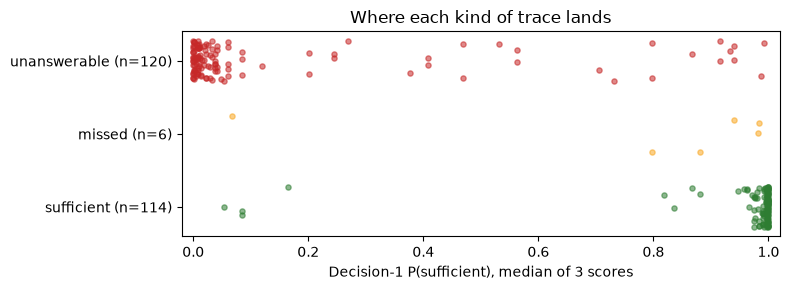

In [12]:
rng = np.random.default_rng(0)
colors = {"sufficient": "#2e7d32", "missed": "#f9a825", "unanswerable": "#c62828"}
fig, ax = plt.subplots(figsize=(8, 3))
for y, label in enumerate(["sufficient", "missed", "unanswerable"]):
    part = traces[traces["label"] == label]
    ax.scatter(part["p_med"], y + rng.uniform(-0.28, 0.28, len(part)), s=14, alpha=0.55, color=colors[label])
ax.set_yticks(range(3), [f"{l} (n={(traces['label'] == l).sum()})" for l in colors])
ax.set_xlabel("Decision-1 P(sufficient), median of 3 scores")
ax.set_title("Where each kind of trace lands")
ax.set_xlim(-0.02, 1.02)
plt.tight_layout()
plt.show()

Sufficient traces stack up near 1 and most unanswerable ones near 0. What the thresholds in the next section have to cope with is the thin scatter in between, and the unanswerable traces that score high at the right edge.

## 9. Choose a threshold per risk tier

The placeholder 0.5 treats every use of an answer the same. In practice the cost of a wrong answer depends on where it goes, so the policy is **one threshold per risk tier**:

| Tier | Where the answer goes | Maximum unsupported-answer rate on `dev` |
|---|---|---|
| `explain` | An engineer reading a cited explanation | 15% |
| `customer_facing` | A reply sent to a customer | 5% |
| `remediate` | An agent that proposes or triggers an action | 0% |

The targets are constraints, not costs, so no dollar figures are invented. For each tier the procedure picks the **lowest** threshold whose unsupported-answer rate on the dev traces stays within the target. Lowest means most answers for the allowed risk. The threshold is placed midway between the chosen dev score and the next one below, so it isn't pinned to a single sample. Dev traces from all four efforts are pooled, which yields one number per tier that works at any effort.

Two baselines use the same procedure. **Always answer** is what a retrieval-only app does. The **reranker gate** thresholds the top reranker score the knowledge base already returns, so it costs nothing extra and is the obvious alternative to try first.

- **When to use it:** answers go to more than one place, and each place tolerates a different rate of wrong answers.
- **What it does:** turns an unsupported-answer target into the lowest probability that meets it on dev, then reports the result on a separate test split.
- **What to adapt:** the tier names and targets, your labeled questions, and the dev/test split.

In [13]:
TIERS = {"explain": 0.15, "customer_facing": 0.05, "remediate": 0.0}
dev, test = traces[traces["split"] == "dev"], traces[traces["split"] == "test"]


def pick_threshold(df, column, target):
    values = sorted(df[column].unique())
    for i, tau in enumerate(values):
        accept = df[column] >= tau
        answered = int(accept.sum())
        if answered and (accept & ~df["suff"]).sum() / answered <= target:
            return round((tau + values[i - 1]) / 2, 3) if i else round(tau, 3)
    return float("inf")  # no threshold meets the target: always escalate


def wilson(k, n, z=1.96):
    if n == 0:
        return 0.0, 0.0
    p, d = k / n, 1 + z * z / n
    center, half = p + z * z / (2 * n), z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return max(0.0, (center - half) / d), min(1.0, (center + half) / d)


def gate_metrics(df, accept):
    answered, bad = int(accept.sum()), int((accept & ~df["suff"]).sum())
    low, high = wilson(bad, answered)
    return {
        "answered": f"{answered}/{len(df)}",
        "unsupported": f"{bad}/{answered}",
        "unsupported_rate": f"{bad / answered:.0%}" if answered else "-",
        "ci95": f"{low:.0%}-{high:.0%}" if answered else "-",
        "coverage": f"{(accept & df['suff']).sum() / max(df['suff'].sum(), 1):.0%}",
        "accepted_unanswerable": int((accept & (df["label"] == "unanswerable")).sum()),
    }


d1_tau = {tier: pick_threshold(dev, "p_med", target) for tier, target in TIERS.items()}
rr_tau = {tier: pick_threshold(dev, "rerank_top", target) for tier, target in TIERS.items()}
print("thresholds chosen on dev:")
print(pd.DataFrame({"decision-1": d1_tau, "reranker": rr_tau}).to_string())

thresholds chosen on dev:
                 decision-1  reranker
explain               0.765     3.875
customer_facing       0.989       inf
remediate             0.994       inf


In [14]:
rows = [{"policy": "always answer", **gate_metrics(test, pd.Series(True, index=test.index))}]
rows.append({"policy": "Decision-1 gate, flat 0.5", **gate_metrics(test, test["p_med"] >= PLACEHOLDER)})
for tier in TIERS:
    rows.append({"policy": f"reranker gate, {tier}", **gate_metrics(test, test["rerank_top"] >= rr_tau[tier])})
for tier in TIERS:
    rows.append({"policy": f"Decision-1 gate, {tier}", **gate_metrics(test, test["p_med"] >= d1_tau[tier])})
table = pd.DataFrame(rows).set_index("policy")
print(f"test split, {len(test)} traces (40 questions x 4 efforts)")
print("unsupported = answered but evidence insufficient; coverage = share of sufficient traces answered")
print(table.to_string())

test split, 160 traces (40 questions x 4 efforts)
unsupported = answered but evidence insufficient; coverage = share of sufficient traces answered
                                 answered unsupported unsupported_rate     ci95 coverage  accepted_unanswerable
policy                                                                                                         
always answer                     160/160      82/160              51%  44%-59%     100%                     76
Decision-1 gate, flat 0.5          87/160       12/87              14%   8%-23%      96%                      7
reranker gate, explain             32/160        6/32              19%   9%-35%      33%                      3
reranker gate, customer_facing      0/160         0/0                -        -       0%                      0
reranker gate, remediate            0/160         0/0                -        -       0%                      0
Decision-1 gate, explain           84/160        9/84              11

Always answering is wrong on 82 of 160 test traces (51%). The flat 0.5 placeholder from section 6 answers 87 and 12 of those are unsupported (14%), which is the cost of using one number for every tier. The reranker gate at the `explain` threshold answers only 32 and 6 of those are unsupported (19%), over its 15% dev target. No reranker threshold met the stricter targets on dev, so for `customer_facing` and `remediate` it escalates everything. The Decision-1 gate answers 84 at `explain` (9 unsupported, 11%, 96% coverage), 60 at `customer_facing` with none unsupported (77% coverage), and 50 at `remediate` with none unsupported (64%).

Two caveats come with these numbers. Zero unsupported answers on a finite test set is still an upper bound: the 95% Wilson interval for 0 of 60 runs up to 6%, and 0 of 50 up to 7%. And the four efforts of one question are correlated, so intervals computed over 160 traces are optimistic. The effective sample is closer to the 40 test questions, and the dev split behind the thresholds is only 20.

One more note on the split: dev question q39 ("How many events failed during the August 2026 ap-south egress IP change?") and test question q42 ("How many deliveries failed during ...") ask about the same incident in almost the same words. q42 is also this recipe's main worked example. It doesn't flatter the results, since it accounts for four of the nine `explain` errors below, but a split by incident would be stricter.

In [15]:
wrong = test[(test["p_med"] >= d1_tau["explain"]) & ~test["suff"]].copy()
wrong["retrieved"] = wrong["doc_ids"].apply(", ".join)
wrong["p_med"] = wrong["p_med"].round(3)
wrong["would_answer_customer_facing"] = wrong["p_med"] >= d1_tau["customer_facing"]
print(f"{len(wrong)} explain-tier answers on the test split were not supported by the retrieved evidence")
print(wrong.sort_values(["qid", "effort"])[["qid", "effort", "category", "label", "p_med", "would_answer_customer_facing", "retrieved"]].to_string(index=False))
print()
for qid in sorted(wrong["qid"].unique()):
    print(qid, QUESTIONS[qid]["question"])

9 explain-tier answers on the test split were not supported by the retrieved evidence
qid  effort  category        label  p_med  would_answer_customer_facing                                                                    retrieved
q21     low multi_doc       missed  0.984                         False           release-notes-v3-0, runbook-signature-failures, release-notes-v2-9
q21  medium multi_doc       missed  0.982                         False           release-notes-v3-0, runbook-signature-failures, release-notes-v2-9
q22    auto multi_doc       missed  0.881                         False                 release-notes-v3-2, delivery-and-retries, release-notes-v3-0
q27     low multi_doc       missed  0.940                         False                        release-notes-v2-9, delivery-and-retries, rate-limits
q28 minimal multi_doc       missed  0.798                         False               runbook-dlq-replay, dead-letter-and-replay, release-notes-v3-2
q42    auto near_mis

The nine `explain` errors are four different kinds, and only some of them are the gate's fault:

- **A real near-miss (q42, 4 traces).** The question asks how many deliveries failed during an incident. The retrieved postmortem is about exactly that incident and says only that fourteen workspaces were affected. Decision-1 scores it 0.92 to 0.94: on topic, but missing the fact. This is the case the `customer_facing` threshold exists for, and none of these four clears it.
- **Label gray zone (q21 twice, q27 once).** The strict label says `missed`, but the retrieved documents do answer the question. For q21 the v3.0 release notes give the 24-hour grace window and the runbook says to compare every `v1` value. For q27 the v2.9 release notes and the retries guide give the 10-second timeout and the eight attempts. Accepting these is arguably correct.
- **A real miss (q28 at `minimal`).** The `Idempotency-Key` answer is in a postmortem that wasn't retrieved, and Decision-1 gave the evidence 0.80. It is below the `customer_facing` threshold, so only the `explain` tier lets it through.
- **A partial one (q22 at `auto`).** Retrieval returned the retries guide and two release notes but not the dead-letter guide that documents the full replay command.

Thresholds say where to cut. **AUROC** says how well the score separates sufficient from insufficient traces regardless of where you cut: 1.0 is perfect and 0.5 is a coin flip. It makes the comparison with the reranker score independent of the threshold-selection procedure.

In [16]:
def auroc(scores, positive):
    ranks = pd.Series(scores).rank(method="average").to_numpy()
    n_pos = int(positive.sum())
    n_neg = len(positive) - n_pos
    return (ranks[positive.to_numpy()].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


def auroc_row(df):
    return {
        "Decision-1 (median of 3)": auroc(df["p_med"], df["suff"]),
        "Decision-1 (single call)": auroc(df["p_first"], df["suff"]),
        "reranker top score": auroc(df["rerank_top"], df["suff"]),
    }


auc = pd.DataFrame({"all efforts": auroc_row(test), **{e: auroc_row(test[test["effort"] == e]) for e in EFFORT_LIST}}).T
print("AUROC on the test split (n = 160 overall, 40 per effort)")
print(auc.round(3).to_string())

AUROC on the test split (n = 160 overall, 40 per effort)
             Decision-1 (median of 3)  Decision-1 (single call)  reranker top score
all efforts                     0.986                     0.986               0.929
minimal                         0.985                     0.988               0.995
low                             0.990                     0.990               0.881
medium                          0.980                     0.980               0.898
auto                            0.990                     0.990               0.965


Decision-1 separates sufficient from insufficient traces with an AUROC of 0.986 overall and 0.980 to 0.990 within each effort. The reranker score is 0.929 overall and swings by effort: at `minimal` it ranks slightly *better* than Decision-1 (0.995 against 0.985), but at `low` and `medium` it falls to 0.881 and 0.898. One plausible reason is that a reranker score is relative to the candidate set the knowledge base assembled, so its scale can move when the retrieval configuration does. This recipe doesn't test that explanation, but it is consistent with why one pooled reranker threshold failed above. Scoring once or taking the median of three gives nearly the same AUROC at every effort. The largest gap is at `minimal` (0.988 against 0.985).

The fair follow-up is to give the reranker its own threshold per effort.

In [17]:
rows = []
for tier in ["explain", "customer_facing"]:
    for effort in EFFORT_LIST:
        dev_e, test_e = dev[dev["effort"] == effort], test[test["effort"] == effort]
        tau_rr = pick_threshold(dev_e, "rerank_top", TIERS[tier])
        rr = gate_metrics(test_e, test_e["rerank_top"] >= tau_rr)
        d1 = gate_metrics(test_e, test_e["p_med"] >= d1_tau[tier])
        rows.append({
            "tier": tier,
            "effort": effort,
            "reranker threshold": tau_rr,
            "reranker unsupported": rr["unsupported"],
            "reranker coverage": rr["coverage"],
            "Decision-1 threshold": d1_tau[tier],
            "Decision-1 unsupported": d1["unsupported"],
            "Decision-1 coverage": d1["coverage"],
        })
print("Test split, 40 questions per effort. Reranker thresholds are picked per effort on that effort's 20 dev traces;")
print("the Decision-1 threshold is the single pooled one from above.")
print(pd.DataFrame(rows).set_index(["tier", "effort"]).to_string())

Test split, 40 questions per effort. Reranker thresholds are picked per effort on that effort's 20 dev traces;
the Decision-1 threshold is the single pooled one from above.
                         reranker threshold reranker unsupported reranker coverage  Decision-1 threshold Decision-1 unsupported Decision-1 coverage
tier            effort                                                                                                                             
explain         minimal               3.301                 0/16               80%                 0.765                   2/21                 95%
                low                     inf                  0/0                0%                 0.765                   3/21                100%
                medium                3.880                 2/10               40%                 0.765                   2/21                 95%
                auto                  3.690                 1/14               65%     

Inside one effort the reranker is competitive. At `minimal` and the `explain` tier its own threshold answers 16 questions with none unsupported (80% coverage), which is cleaner than Decision-1's 2 unsupported among 21 answers (95% coverage). It's a trade of coverage for precision, and it costs no extra call. Elsewhere the per-effort threshold is hard to set from 20 dev traces: it comes out as `inf` (no threshold meets the target) at `low` for both tiers and at `auto` for `customer_facing`, and at `medium` the chosen threshold lets 2 unsupported answers through at both tiers.

Decision-1's one pooled threshold gives no unsupported answers at `customer_facing` at all four efforts, with 70% to 80% coverage. So the reranker isn't a bad signal. Its scale depends on how the candidates were retrieved, so each retrieval configuration needs its own validated threshold. If you ship one fixed configuration and have enough labeled questions to calibrate it, try the free reranker gate first. If the configuration will change, as it does in a retry cascade, a score with a stable meaning is worth the extra call.

In [18]:
bins = [-0.001, 0.05, 0.2, 0.5, 0.8, 0.95, 1.0]
reliability = (
    traces.assign(band=pd.cut(traces["p_med"], bins))
    .groupby("band", observed=True)
    .agg(traces=("qid", "size"), sufficient=("suff", "mean"), unanswerable=("label", lambda s: (s == "unanswerable").mean()))
)
print("Reliability: how often evidence really was sufficient, by Decision-1 probability (all splits)")
print(reliability.round(2).to_string())

Reliability: how often evidence really was sufficient, by Decision-1 probability (all splits)
                traces  sufficient  unanswerable
band                                            
(-0.001, 0.05]      85        0.00          1.00
(0.05, 0.2]         15        0.27          0.67
(0.2, 0.5]          10        0.00          1.00
(0.5, 0.8]           8        0.00          0.88
(0.8, 0.95]         13        0.38          0.46
(0.95, 1.0]        109        0.96          0.02


The two ends can be trusted. None of the 85 traces at or below 0.05 had sufficient evidence, and 96% of the 109 above 0.95 did (2% were unanswerable questions). The middle is different. The 0.8 to 0.95 band is only 38% sufficient and the 0.5 to 0.8 band has none, so a probability of 0.9 doesn't mean "90% likely to be sufficient". It's a ranking signal, not a calibrated frequency. Two things sit in that band: gray-zone labels, and topical near-misses like q42 (0.91 to 0.94) and q39 (0.71 to 0.80), where the retrieved documents are about exactly the right event but not the asked detail. This is why the `customer_facing` and `remediate` thresholds are above 0.98 and not around 0.8.

In [19]:
per_effort = []
for effort in EFFORT_LIST:
    part = test[test["effort"] == effort]
    per_effort.append({"effort": effort, "policy": "always answer", **gate_metrics(part, pd.Series(True, index=part.index))})
    per_effort.append({"effort": effort, "policy": "Decision-1, customer_facing", **gate_metrics(part, part["p_med"] >= d1_tau["customer_facing"])})
print(pd.DataFrame(per_effort).set_index(["effort", "policy"]).to_string())

                                    answered unsupported unsupported_rate     ci95 coverage  accepted_unanswerable
effort  policy                                                                                                    
minimal always answer                  40/40       20/40              50%  35%-65%     100%                     19
        Decision-1, customer_facing    16/40        0/16               0%   0%-19%      80%                      0
low     always answer                  40/40       22/40              55%  40%-69%     100%                     19
        Decision-1, customer_facing    14/40        0/14               0%   0%-22%      78%                      0
medium  always answer                  40/40       20/40              50%  35%-65%     100%                     19
        Decision-1, customer_facing    14/40        0/14               0%   0%-22%      70%                      0
auto    always answer                  40/40       20/40              50%  35%-6

At `customer_facing` the gate gives no unsupported answers at any effort, while still answering 70% to 80% of the sufficient traces. That's the property the next section depends on: one threshold, whichever effort produced the evidence.

## 10. Escalate through retrieval effort

A gate that only says "no" leaves the user with nothing. The other option is to **retry at a higher retrieval effort** before giving up: `minimal` first because it is fastest and plans nothing, then `low`, then `medium`. After the last attempt the application escalates.

- **When to use it:** you can afford more than one retrieval per question, and an escalation costs a person's time.
- **What it does:** tries `minimal`, then `low`, then `medium`, and stops at the first attempt that clears the tier's threshold.
- **What to adapt:** the list of efforts and their order.

The cascade is replayed from the recorded traces, so no new calls are made. For each question it takes the `minimal` trace, answers if the probability clears the tier's threshold, and otherwise moves to the `low` trace, and so on. Latency and tokens are summed over every attempt actually made, so retries show up in the cost. Each decision here uses the median of 3 Decision-1 calls, so every attempt costs three Decision-1 requests.

In [20]:
CASCADE = ["minimal", "low", "medium"]
SCORES_PER_DECISION = 3
by_key = {(r.qid, r.effort): r for r in traces.itertuples()}
test_qids = sorted(test["qid"].unique())


def run_strategy(qids, tau, efforts, floor=0.0):
    rows = []
    for qid in qids:
        attempts = []
        for effort in efforts:
            attempts.append(by_key[(qid, effort)])
            if attempts[-1].p_med >= tau or attempts[-1].p_med < floor:
                break
        last = attempts[-1]
        rows.append({
            "qid": qid,
            "decision": "answered" if last.p_med >= tau else "escalated",
            "stop": last.effort,
            "label": last.label,
            "answerable": QUESTIONS[qid]["answerable"],
            "attempts": len(attempts),
            "kb_s": sum(a.kb_ms for a in attempts) / 1000,
            "dm_s": sum(a.dm_ms_med for a in attempts) * SCORES_PER_DECISION / 1000,
            "planner_tokens": sum(a.planner_tokens for a in attempts),
            "dm_tokens": sum(a.dm_in_tokens for a in attempts) * SCORES_PER_DECISION,
        })
    return pd.DataFrame(rows)


def summarize(df):
    answered = df[df["decision"] == "answered"]
    supported = int((answered["label"] == "sufficient").sum())
    return {
        "answered": f"{len(answered)}/{len(df)}",
        "unsupported": f"{len(answered) - supported}/{len(answered)}",
        "supported": supported,
        "coverage": f"{supported / int(df['answerable'].sum()):.0%}",
        "latency_s": round((df["kb_s"] + df["dm_s"]).mean(), 1),
        "planner_tok": int(df["planner_tokens"].mean()),
        "dm_in_tok": int(df["dm_tokens"].mean()),
    }


strategies = {"minimal only": ["minimal"], "medium only": ["medium"], "cascade": CASCADE}
rows = []
for tier in TIERS:
    for name, efforts in strategies.items():
        rows.append({"tier": tier, "strategy": name, **summarize(run_strategy(test_qids, d1_tau[tier], efforts))})
cascade_table = pd.DataFrame(rows).set_index(["tier", "strategy"])
print("test split, 40 questions. coverage = supported answers / answerable questions; per-question means for latency and tokens")
print(cascade_table.to_string())

test split, 40 questions. coverage = supported answers / answerable questions; per-question means for latency and tokens
                             answered unsupported  supported coverage  latency_s  planner_tok  dm_in_tok
tier            strategy                                                                                
explain         minimal only    21/40        2/21         19      90%        1.6            0       2742
                medium only     21/40        2/21         19      90%        5.1         2699       3115
                cascade         22/40        2/22         20      95%        5.7         1627       5412
customer_facing minimal only    16/40        0/16         16      76%        1.6            0       2742
                medium only     14/40        0/14         14      67%        5.1         2699       3115
                cascade         18/40        0/18         18      86%        6.8         2095       6265
remediate       minimal only    12/40  

Spending more on a single attempt doesn't buy coverage. At `customer_facing`, `medium only` answers fewer questions than `minimal only` (14 against 16, 67% against 76% coverage) at three times the latency and about 2.7k planner tokens. Retrying *across* efforts does help: the cascade answers 18 with no unsupported answers (86% coverage), because each effort retrieves a slightly different top 3. It costs a mean of 6.8 seconds against 1.6 for `minimal only`, and about 2.3 times the Decision-1 input tokens (6.3k against 2.7k; output tokens aren't in the traces) since every retry is scored again. At the `explain` tier the cascade adds 5 points of coverage for 4 more seconds, which most applications wouldn't pay for.

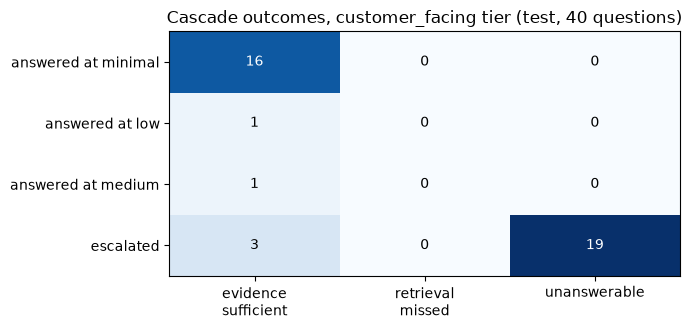

Answered only after a retry: 2 (of which supported: 2)
Escalated although the final evidence was sufficient: 3
Escalated questions that were unanswerable: 19


In [21]:
tier = "customer_facing"
outcome = run_strategy(test_qids, d1_tau[tier], CASCADE)
outcome["outcome"] = np.where(outcome["decision"] == "escalated", "escalated", "answered at " + outcome["stop"])
order = ["answered at minimal", "answered at low", "answered at medium", "escalated"]
matrix = pd.crosstab(outcome["outcome"], outcome["label"]).reindex(index=order, columns=["sufficient", "missed", "unanswerable"], fill_value=0)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.imshow(matrix.to_numpy(), cmap="Blues", aspect="auto")
ax.set_xticks(range(3), ["evidence\nsufficient", "retrieval\nmissed", "unanswerable"])
ax.set_yticks(range(4), order)
for (i, j), value in np.ndenumerate(matrix.to_numpy()):
    ax.text(j, i, value, ha="center", va="center", color="white" if value > matrix.to_numpy().max() / 2 else "black")
ax.set_title(f"Cascade outcomes, {tier} tier (test, 40 questions)")
plt.tight_layout()
plt.show()

rescued = outcome[(outcome["decision"] == "answered") & (outcome["stop"] != "minimal")]
print(f"Answered only after a retry: {len(rescued)} (of which supported: {int((rescued['label'] == 'sufficient').sum())})")
print(f"Escalated although the final evidence was sufficient: {int(((outcome['decision'] == 'escalated') & (outcome['label'] == 'sufficient')).sum())}")
print(f"Escalated questions that were unanswerable: {int(((outcome['decision'] == 'escalated') & (outcome['label'] == 'unanswerable')).sum())}")

Two questions were rescued by a retry. q28 is the clean example: at `minimal` the retrieved set had the replay guide but not the July bulk-replay postmortem, and P was 0.80. `low` retrieved the postmortem and P rose to 0.999. The other rescue, q15, is a margin case: the three attempts scored 0.974, 0.971 and 0.990 against a threshold of 0.989, which says more about the threshold than about retrieval.

Three escalations had sufficient evidence in the last attempt. q27 and q22 scored just under the threshold on most attempts (q27 between 0.94 and 0.96, q22 at 0.97 on two of three), which is the price of a strict tier on multi-document questions. q09 is more interesting. `minimal`, `auto` and `medium` retrieved the v3.0 release notes, which say Pro keeps the dead-letter queue for 7 days, next to the current guide that says 14. P was 0.05 to 0.09. `low` retrieved the v3.2 release notes, which explain that Pro went from 7 to 14 days, and P was 0.98. Stale documents sitting next to current ones lower the score, and the score recovers when the retrieved set explains the change. Fixing the corpus would help this question more than tuning the gate would.

Most of the cascade's time goes to questions that end up escalated. An unanswerable question runs all three efforts before the application gives up. One way to cut that is a **floor**: if an attempt scores below it, stop retrying, because a higher effort is unlikely to rescue the question. The floor below is chosen on dev only, as the lowest probability that any sufficient dev trace received.

- **When to use it:** many of your questions are unanswerable and each retry adds latency.
- **What it does:** stops retrying as soon as an attempt scores below the floor.
- **What to adapt:** the floor, re-derived from your own dev traces.

In [22]:
floor = round(dev.loc[dev["suff"], "p_med"].min(), 3)
rows = []
for tier in TIERS:
    for name, f in [("full cascade", 0.0), (f"stop below {floor}", floor)]:
        out = run_strategy(test_qids, d1_tau[tier], CASCADE, f)
        rows.append({"tier": tier, "retry rule": name, "attempts": int(out["attempts"].sum()), **summarize(out)})
print(f"test split, 40 questions. floor = lowest P(sufficient) among sufficient dev traces = {floor}")
print(pd.DataFrame(rows).set_index(["tier", "retry rule"]).drop(columns=["planner_tok", "dm_in_tok"]).to_string())

test split, 40 questions. floor = lowest P(sufficient) among sufficient dev traces = 0.165
                                  attempts answered unsupported  supported coverage  latency_s
tier            retry rule                                                                    
explain         full cascade            77    22/40        2/22         20      95%        5.7
                stop below 0.165        45    21/40        2/21         19      90%        2.1
customer_facing full cascade            87    18/40        0/18         18      86%        6.8
                stop below 0.165        53    18/40        0/18         18      86%        3.0
remediate       full cascade            95    13/40        0/13         13      62%        7.7
                stop below 0.165        61    13/40        0/13         13      62%        3.8


At `customer_facing` the floor gives identical answers (18 answered, none unsupported, 86% coverage) with 53 attempts instead of 87 and a mean latency of 3.0 seconds instead of 6.8. At `explain` it saves 32 attempts but loses one rescue, q09, whose first attempt scored 0.085 before the retrieved set changed: coverage drops from 95% to 90%. The floor rests on one dev trace (the next-lowest sufficient dev trace scored 0.82), so treat it as a knob to validate on your own data, not a default.

## 11. How much to trust the probability

Two things can move a probability without the evidence changing: calling the same request twice, and rewording the gate question. Both decide how much margin to leave around a threshold.

**Repeat calls.** Every trace was scored three times on identical input.

In [23]:
traces["p_range"] = traces["p"].apply(lambda v: max(v) - min(v))
band = traces[(traces["p_med"] > 0.05) & (traces["p_med"] < 0.95)]
print(f"Traces scored identically 3 times: {len(traces)}")
print(f"  range under 0.01 across the 3 calls : {(traces['p_range'] < 0.01).mean():.0%} of traces")
print(f"  largest range                        : {traces['p_range'].max():.3f}")
print(f"  traces with median between 0.05-0.95: {len(band)}; their mean range {band['p_range'].mean():.3f}, max {band['p_range'].max():.3f}")
print()
rows = []
for tier, tau in d1_tau.items():
    flips = traces["p"].apply(lambda v: len({x >= tau for x in v}) > 1)
    rows.append({"tier": tier, "threshold": tau, "traces whose 3 calls disagree": int(flips.sum()), "share": f"{flips.mean():.1%}"})
print(pd.DataFrame(rows).set_index("tier").to_string())

Traces scored identically 3 times: 240
  range under 0.01 across the 3 calls : 80% of traces
  largest range                        : 0.184
  traces with median between 0.05-0.95: 46; their mean range 0.045, max 0.184

                 threshold  traces whose 3 calls disagree share
tier                                                           
explain              0.765                              3  1.2%
customer_facing      0.989                              8  3.3%
remediate            0.994                              0  0.0%


Most scores barely move: 80% of traces have a range under 0.01 across the three calls, and the largest is 0.184. The movement is in the middle, where it matters. The 46 traces with a median between 0.05 and 0.95 have a mean range of 0.045. At a threshold of 0.989, 8 traces (3.3%) are accepted or rejected depending on which call you look at, and 3 (1.2%) at 0.765. None flip at the `remediate` threshold of 0.994.

In [24]:
thr_first = {tier: pick_threshold(dev, "p_first", target) for tier, target in TIERS.items()}
rows = []
for tier in TIERS:
    rows.append({"tier": tier, "scoring": "single call", "threshold": thr_first[tier], **gate_metrics(test, test["p_first"] >= thr_first[tier])})
    rows.append({"tier": tier, "scoring": "median of 3", "threshold": d1_tau[tier], **gate_metrics(test, test["p_med"] >= d1_tau[tier])})
print("Test split, thresholds re-selected on dev for each scoring method")
print(pd.DataFrame(rows).set_index(["tier", "scoring"]).to_string())

Test split, thresholds re-selected on dev for each scoring method
                             threshold answered unsupported unsupported_rate    ci95 coverage  accepted_unanswerable
tier            scoring                                                                                             
explain         single call      0.766   84/160        9/84              11%  6%-19%      96%                      4
                median of 3      0.765   84/160        9/84              11%  6%-19%      96%                      4
customer_facing single call      0.989   59/160        0/59               0%   0%-6%      76%                      0
                median of 3      0.989   60/160        0/60               0%   0%-6%      77%                      0
remediate       single call      0.993   50/160        0/50               0%   0%-7%      64%                      0
                median of 3      0.994   50/160        0/50               0%   0%-7%      64%                      

On the test split, one call and the median of three give the same results at `explain` and `remediate`, and 59 against 60 answers at `customer_facing`, with no unsupported answers in either. The aggregate metrics don't need three calls. The recipe keeps three for a per-decision reason: with a threshold at 0.989, a single call can land on either side for the same input in about 3% of traces. The cost is three Decision-1 requests per attempt. `scores_per_decision` in `policy.json` lets you drop it to 1 and take the latency and token savings if your own validation shows the same.

**Wording.** The medium traces were also scored with two reworded versions of the gate question. The thresholds below are *not* re-tuned for the new wordings. That is the situation after someone edits the question in production without re-validating.

In [25]:
medium = traces[traces["effort"] == "medium"].copy()
medium["para_a"], medium["para_b"] = medium["p_alt"].str[0], medium["p_alt"].str[1]
medium_test = medium[medium["split"] == "test"]
tau = thr_first["customer_facing"]
base_accept = medium_test["p_first"] >= tau
rows = []
for name, column in [("base wording", "p_first"), ("paraphrase A", "para_a"), ("paraphrase B", "para_b")]:
    accept = medium_test[column] >= tau
    rows.append({
        "wording": name,
        "AUROC": round(auroc(medium_test[column], medium_test["suff"]), 3),
        "rank corr with base": round(medium[column].rank().corr(medium["p_first"].rank()), 3),
        "same decision as base": f"{(accept == base_accept).mean():.0%}",
        **gate_metrics(medium_test, accept),
    })
print(f"medium traces on the test split (n={len(medium_test)}), customer_facing threshold {tau} from the base wording")
print(pd.DataFrame(rows).set_index("wording").to_string())

medium traces on the test split (n=40), customer_facing threshold 0.989 from the base wording
              AUROC  rank corr with base same decision as base answered unsupported unsupported_rate    ci95 coverage  accepted_unanswerable
wording                                                                                                                                     
base wording  0.980                1.000                  100%    14/40        0/14               0%  0%-22%      70%                      0
paraphrase A  0.972                0.994                  100%    14/40        0/14               0%  0%-22%      70%                      0
paraphrase B  0.980                0.994                   92%    17/40        0/17               0%  0%-18%      85%                      0


The reworded questions rank traces almost the same way (rank correlation 0.994 or higher, AUROC 0.972 to 0.980). The same threshold doesn't make the same decisions, though. Paraphrase B accepted 17 questions instead of 14 and agreed with the base wording on 92% of them (3 questions changed). All three were supported here, but this is one of two rewordings on 40 test questions, so read it as a warning and not a measurement: the scale can move. A threshold belongs to a specific wording, which is why `policy.json` stores the gate question next to the thresholds, and why editing the question means re-running section 9.

## 12. Package the policy

Everything the application needs at run time fits in one small file, and everything it does fits in one small class. `policy.json` records which thresholds apply, which gate question they were validated against, and the evidence that supports them. The version of the gate question matters: a threshold is only meaningful for the wording and model it was tuned on.

In [26]:
def tier_result(tau):
    s = summarize(run_strategy(test_qids, tau, CASCADE))
    return {"answered": s["answered"], "unsupported": s["unsupported"], "coverage": s["coverage"]}


policy = {
    "version": 1,
    "collected_at": trace_meta["collected_at"],
    "retrieval": {"k": K, "efforts": CASCADE, "planner_model": AOAI_GPT},
    "gate": {
        "model": DECISION_DEPLOYMENT,
        "question": SUFFICIENT,
        "scores_per_decision": SCORES_PER_DECISION,
        "aggregate": "median",
    },
    "tiers": {
        tier: {
            "max_unsupported_rate_on_dev": TIERS[tier],
            "answer_at": None if np.isinf(tau) else tau,
            "test_result": tier_result(tau),
        }
        for tier, tau in d1_tau.items()
    },
    "validated_on": {
        "dev_questions": int(dev["qid"].nunique()),
        "test_questions": int(test["qid"].nunique()),
        "traces": len(traces),
    },
}
(DATA / "policy.json").write_text(json.dumps(policy, indent=2) + "\n", encoding="utf-8")
print(json.dumps(policy["tiers"], indent=2))

{
  "explain": {
    "max_unsupported_rate_on_dev": 0.15,
    "answer_at": 0.765,
    "test_result": {
      "answered": "22/40",
      "unsupported": "2/22",
      "coverage": "95%"
    }
  },
  "customer_facing": {
    "max_unsupported_rate_on_dev": 0.05,
    "answer_at": 0.989,
    "test_result": {
      "answered": "18/40",
      "unsupported": "0/18",
      "coverage": "86%"
    }
  },
  "remediate": {
    "max_unsupported_rate_on_dev": 0.0,
    "answer_at": 0.994,
    "test_result": {
      "answered": "13/40",
      "unsupported": "0/13",
      "coverage": "62%"
    }
  }
}


`EvidenceGate` is the runtime version of the replay in section 10. It takes its collaborators as arguments, `retrieve(question, effort)` and `score(question, docs)`, so the same class runs against the live knowledge base here and against stubs in a unit test. The cell ends with a stub test of the three outcomes: answer, escalate below the threshold, and escalate on an error. It never returns an answer on its own authority: it returns a decision, the evidence it was based on, and every attempt it made. It also fails closed. If retrieval or scoring raises, the decision is `escalate` with the reason `gate_error`, because an error should never turn into an answer.

In [27]:
class EvidenceGate:
    def __init__(self, policy, tier, retrieve, score):
        self.tier, self.retrieve, self.score = tier, retrieve, score
        self.efforts = policy["retrieval"]["efforts"]
        self.n_scores = policy["gate"]["scores_per_decision"]
        self.answer_at = policy["tiers"][tier]["answer_at"]  # None means this tier never answers

    def decide(self, question):
        attempts, p, evidence = [], 0.0, {"docs": []}
        try:
            for effort in self.efforts:
                evidence = self.retrieve(question, effort)
                p = float(np.median([self.score(question, evidence["docs"]) for _ in range(self.n_scores)]))
                attempts.append({"effort": effort, "doc_ids": evidence["doc_ids"], "p": round(p, 3)})
                if self.answer_at is not None and p >= self.answer_at:
                    return {"decision": "answer", "tier": self.tier, "p": p, "evidence": evidence["docs"], "attempts": attempts}
        except Exception as exc:
            # fail closed: if retrieval or scoring breaks, the safe decision is to escalate
            return {"decision": "escalate", "reason": "gate_error", "error": type(exc).__name__,
                    "tier": self.tier, "p": p, "evidence": [], "attempts": attempts}
        reason = "tier_never_answers" if self.answer_at is None else "below_threshold"
        return {"decision": "escalate", "reason": reason, "tier": self.tier, "p": p, "evidence": evidence["docs"], "attempts": attempts}


def make_gate(tier):
    return EvidenceGate(
        policy,
        tier,
        retrieve=lambda question, effort: retrieve_at(question, effort),
        score=lambda question, docs: score_sufficiency(question, docs)[0],
    )


def broken_retrieve(question, effort):
    raise TimeoutError("knowledge base unreachable")


stub_evidence = {"docs": [{"title": "stub"}], "doc_ids": ["stub"]}
stub_gates = {
    "high score": EvidenceGate(policy, "explain", lambda q, e: stub_evidence, lambda q, d: 0.99),
    "low score": EvidenceGate(policy, "explain", lambda q, e: stub_evidence, lambda q, d: 0.10),
    "retrieval fails": EvidenceGate(policy, "explain", broken_retrieve, lambda q, d: 0.99),
}
for name, stub_gate in stub_gates.items():
    out = stub_gate.decide("any question")
    print(f"{name:16} -> {out['decision']:9} {out.get('reason', '')}")

high score       -> answer    
low score        -> escalate  below_threshold
retrieval fails  -> escalate  gate_error


An escalation should carry enough for a person to pick the question up. Decision-1 handles that too, with two more typed questions in one call: a `choice` for the owning team and a `score` for severity. The `score` type takes an ordered list of levels and returns a probability for each, so the packet reports the most likely level and how sure the model is. The state is the question and the titles of what was retrieved.

In [28]:
HANDOFF = {
    "team": {
        "type": "choice",
        "instructions": "Which team should take this question?",
        "criteria": {
            "delivery": "Webhook delivery, retries, dead-letter queue, replay, endpoint health",
            "security": "Signing secrets, signature verification, mutual TLS, IP allowlists",
            "platform": "API behavior, rate limits, payload limits, regions, data residency, event filtering",
            "account": "Plans, pricing, quotas, billing, contracts",
        },
    },
    "severity": {
        "type": "score",
        "instructions": "How urgent is this for the customer?",
        "criteria": ["Curiosity", "Degraded delivery", "Production outage"],
    },
}


def handoff_packet(question, evidence_docs):
    state = json.dumps({"question": question, "retrieved_titles": [d["title"] for d in evidence_docs]})
    answers, _ = decision.ask(state, HANDOFF)
    severity = answers["severity"]
    level = max(severity["probabilities"], key=severity["probabilities"].get)
    return {
        "team": answers["team"]["choice"],
        "team_confidence": round(answers["team"]["confidence"], 2),
        "severity": severity["legend"][level],
        "severity_probability": round(severity["probabilities"][level], 2),
    }


packet_question = "How much does a dedicated egress IP cost per month, and can we get one before our launch tomorrow?"
packet_docs = [DOCS[i] for i in ["ip-allowlist", "runbook-egress-ip-change", "regions-and-residency"]]
print(packet_question)
print(handoff_packet(packet_question, packet_docs))

How much does a dedicated egress IP cost per month, and can we get one before our launch tomorrow?


{'team': 'account', 'team_confidence': 0.99, 'severity': 'Curiosity', 'severity_probability': 0.68}


Treat the packet as a triage hint. The team choice came back confident, but the severity is weaker: the launch-tomorrow question above was labeled `Curiosity` even though it mentions a deadline. This recipe validated the gate on labeled questions, not the handoff fields. Before routing on severity, label a few tickets and check it the way sections 8 and 9 check the gate.

Before an agent uses the gate, check that the live class agrees with the replay. It is the same logic, but retrieval and scoring are fresh calls, so a few differences are expected near a threshold.

In [29]:
tier = "customer_facing"
gate = make_gate(tier)
replayed = run_strategy(test_qids, d1_tau[tier], CASCADE).set_index("qid")
check_ids = ["q01", "q11", "q28", "q27", "q35", "q42", "q51"]
rows = []
for qid in check_ids:
    live = gate.decide(QUESTIONS[qid]["question"])
    rows.append({
        "qid": qid,
        "category": QUESTIONS[qid]["category"],
        "live decision": live["decision"],
        "live stop": live["attempts"][-1]["effort"],
        "live P": round(live["p"], 3),
        "replay decision": {"answered": "answer", "escalated": "escalate"}[replayed.loc[qid, "decision"]],
        "replay stop": replayed.loc[qid, "stop"],
    })
live_check = pd.DataFrame(rows).set_index("qid")
print(live_check.to_string())
print(f"\nSame decision as the replay: {(live_check['live decision'] == live_check['replay decision']).sum()}/{len(live_check)}")

       category live decision live stop  live P replay decision replay stop
qid                                                                        
q01  single_doc        answer   minimal   0.999          answer     minimal
q11  single_doc        answer   minimal   0.999          answer     minimal
q28   multi_doc        answer       low   0.999          answer         low
q27   multi_doc      escalate    medium   0.958        escalate      medium
q35     partial      escalate    medium   0.009        escalate      medium
q42   near_miss      escalate    medium   0.924        escalate      medium
q51  off_corpus      escalate    medium   0.321        escalate      medium

Same decision as the replay: 7/7


All seven decisions, and the effort each one stopped at, matched the replay. The case to watch is q27, which scores a little under 0.989 and was escalated. It is a stable escalation, not a coin flip: across the recorded traces its scores stay between 0.915 and 0.977 at every effort. The calls that land on either side of the threshold are the 3% of traces in section 11 whose scores sit between 0.982 and 0.992, and q27 is not one of them. q42 sits further below, around 0.92.

## 13. Put the gate behind a Foundry agent

The gate becomes a **function tool**: the agent calls `ground_with_policy(question)`, the function runs the gate, and the agent is instructed to answer only from what comes back, or to hand over when the decision is `escalate`.

- **When to use it:** an agent talks to users directly and you want the policy enforced outside the model.
- **What it does:** exposes retrieval and the gate as one tool that returns either evidence or an escalation with a handoff packet.
- **What to adapt:** the tier bound in the closure, the agent instructions, and the handoff fields.

Two choices carry the safety of this design:

- **The tier is not a tool argument.** The model decides what to ask, not how much risk to accept. The tier is bound in the closure from the caller's trusted context, here the application that created the agent session.
- **The agent's instructions forbid answering from its own knowledge on `escalate`.** A model that can answer anyway makes the gate decorative, so check this behavior in your own evaluation set and not only in the instructions.

In [30]:
from azure.ai.projects import AIProjectClient
from azure.ai.projects.models import FunctionTool, PromptAgentDefinition

PROJECT_ENDPOINT = env("FOUNDRY_PROJECT_ENDPOINT", required=False)
agent = None


def make_ground_tool(tier):
    gate = make_gate(tier)

    def ground_with_policy(question):
        result = gate.decide(question)
        ground_with_policy.attempts = result["attempts"]  # kept for display, not sent to the model
        if result["decision"] == "answer":
            return {
                "decision": "answer",
                "evidence": [{"id": d["id"], "title": d["title"], "text": d["content"]} for d in result["evidence"]],
            }
        try:
            handoff = handoff_packet(question, result["evidence"])
        except Exception:
            handoff = None
        if result["reason"] == "gate_error":
            reason = "The documentation could not be checked just now."
        else:
            reason = "The retrieved documentation is not sufficient to answer this reliably."
        return {"decision": "escalate", "reason": reason, "handoff": handoff}

    return ground_with_policy


AGENT_INSTRUCTIONS = """You answer questions about Relay, a webhook delivery service.
Call ground_with_policy exactly once with the user's question, verbatim.
If the decision is "answer", reply in at most four sentences using only the returned evidence, and cite document ids in square brackets.
If the decision is "escalate", do not answer the question from your own knowledge. In two sentences, say you are handing it to the named team and why, or that a person will follow up if no team is named."""

ground_tool = FunctionTool(
    name="ground_with_policy",
    description="Retrieve evidence from the Relay documentation and decide whether it is sufficient to answer.",
    parameters={
        "type": "object",
        "properties": {"question": {"type": "string", "description": "The user's question, verbatim."}},
        "required": ["question"],
        "additionalProperties": False,
    },
    strict=True,
)
if PROJECT_ENDPOINT:
    project = AIProjectClient(endpoint=PROJECT_ENDPOINT, credential=credential)
    agents_openai = project.get_openai_client()
    agent = project.agents.create_version(
        agent_name=f"relay-gated-support-{RUN}",
        definition=PromptAgentDefinition(model=AOAI_GPT, instructions=AGENT_INSTRUCTIONS, tools=[ground_tool]),
    )
    print("Created agent version", agent.name, agent.version)
else:
    print("FOUNDRY_PROJECT_ENDPOINT is not set, so the agent demo is skipped.")

Created agent version relay-gated-support-a9371c 1


In [31]:
def ask_agent(question, tier="customer_facing"):
    tool = make_ground_tool(tier)
    ref = {"agent_reference": {"name": agent.name, "type": "agent_reference"}}
    response = agents_openai.responses.create(input=question, extra_body=ref)
    calls = [item for item in response.output if item.type == "function_call"]
    if not calls:
        return {"tool_result": None, "attempts": [], "reply": response.output_text}
    outputs, results = [], []
    for call in calls:
        result = tool(**json.loads(call.arguments))
        results.append(result)
        outputs.append({"type": "function_call_output", "call_id": call.call_id, "output": json.dumps(result)})
    final = agents_openai.responses.create(input=outputs, previous_response_id=response.id, extra_body=ref)
    return {"tool_result": results[0], "attempts": tool.attempts, "reply": final.output_text}


def show(question, tier="customer_facing"):
    out = ask_agent(question, tier)
    result = out["tool_result"] or {}
    path = " -> ".join(f"{a['effort']} P={a['p']:.3f}" for a in out["attempts"]) or "no tool call"
    print(f"Q: {question}")
    print(f"   gate: {path}  =>  {result.get('decision', 'none')}" + (f"  {result['handoff']}" if "handoff" in result else ""))
    print(f"A: {out['reply']}\n")


if agent is not None:
    # answered at the first attempt
    show(QUESTIONS["q01"]["question"])
    # a retry rescues it: minimal retrieves too little, low finds the postmortem
    show(QUESTIONS["q28"]["question"])
    # a near-miss: the incident is documented, the number asked for is not
    show(QUESTIONS["q42"]["question"])
    # the same near-miss under a lower-risk tier
    show(QUESTIONS["q42"]["question"], tier="explain")

Q: How many delivery attempts does a webhook get on API v3, and over what period?
   gate: minimal P=0.999  =>  answer
A: On API v3, a webhook delivery gets 8 attempts in total, with retries on an exponential schedule: 10 seconds, 1 minute, 5 minutes, 30 minutes, 2 hours, 6 hours, and 12 hours, so the last attempt happens about 20.6 hours after the first. This is an increase from API v2, which had 5 attempts over about 3.6 hours. The retry schedule and periods are documented in API v3 release notes and the delivery and retries documentation [delivery-and-retries][release-notes-v3-0].



Q: What is the default replay rate per endpoint, and what should I send on a bulk replay request so a client timeout does not cause duplicates?
   gate: minimal P=0.867 -> low P=0.999  =>  answer
A: The default replay rate is 50 deliveries per second per endpoint, but you can lower it with the `--rate` option if needed [dead-letter-and-replay][runbook-dlq-replay]. To avoid duplicates when a bulk replay request times out, always send an `Idempotency-Key` header in your request; if you retry with the same key, Relay will return the original replay instead of starting a new one [pm-2026-07-bulk-replay-duplicates]. Additionally, you should list existing replays before retrying after a timeout. Receivers should de-duplicate on `Relay-Event-Id`, as delivery is at-least-once [runbook-dlq-replay][pm-2026-07-bulk-replay-duplicates].



Q: How many deliveries failed during the August 2026 ap-south egress IP change?
   gate: minimal P=0.924 -> low P=0.924 -> medium P=0.867  =>  escalate  {'team': 'delivery', 'team_confidence': 0.87, 'severity': 'Curiosity', 'severity_probability': 0.56}
A: I am handing your question to the delivery team because the available documentation does not provide enough information to reliably answer how many deliveries failed during the August 2026 ap-south egress IP change. Someone from the team will follow up with the accurate data.



Q: How many deliveries failed during the August 2026 ap-south egress IP change?
   gate: minimal P=0.915  =>  answer
A: During the August 2026 ap-south egress IP change, 14 workspaces experienced delivery failures due to connection errors until they updated their allowlists to include the new egress range, causing their firewalls to drop deliveries. The failures lasted up to 4 hours for the last affected customer, and all failed deliveries were later replayed after resolution [pm-2026-08-ap-south-egress-ip-change].



The first two behave as the replay predicted. q01 is answered at `minimal`. The bulk-replay question needs a retry: `minimal` retrieved the replay guide without the July postmortem and scored below the 0.989 threshold, `low` retrieved the postmortem and scored 0.999, and the agent's answer cites it for the `Idempotency-Key` advice. The near-miss is escalated at `customer_facing` with a packet naming the owning team, and the agent hands over without guessing at a count. The same question at `explain` clears that tier's 0.765 on the first attempt, because the postmortem is about the right incident. The answer it gives is careful, but it reports the affected workspaces and not the number of failed deliveries, which is what was asked. That is the failure the stricter tier is there to catch.

## 14. Takeaways

### What to take away

- **Add a sufficiency gate to retrieval.** A retrieval call returns documents whether or not they answer the question. On the 160 test traces, answering every time was unsupported 51% of the time. The Decision-1 gate at the `customer_facing` tier answered 60 with none unsupported and still answered 77% of the traces whose evidence was sufficient.
- **The application owns the threshold.** One probability served three tiers: 0.765, 0.989 and 0.994, each the lowest threshold that met that tier's unsupported-answer target on dev. A single 0.5, the placeholder used in section 6, would have given 12 unsupported answers out of 87 on the test split (14%): near the `explain` budget and far above the two stricter tiers.
- **A score with a stable meaning lets you retry.** One Decision-1 threshold held at all four retrieval efforts. A reranker threshold needed one per effort, and for some efforts no threshold met the target on 20 dev traces. Retrying across efforts raised `customer_facing` coverage from 76% to 86% with no unsupported answers. Spending more on a single `medium` attempt lowered it to 67%.
- **The policy ships as two small artifacts.** `policy.json` holds the thresholds with the gate question and the evidence behind them. `EvidenceGate` runs them against any `retrieve` and `score` callables. The agent cannot choose its own tier.

### Where it breaks

- **On-topic evidence that lacks the fact.** q42 asks for a number the postmortem doesn't give. Decision-1 scored it 0.92 to 0.94, high enough for `explain` and below `customer_facing`. A low-risk tier will pass answers like this.
- **A probability is not a frequency in the middle.** Traces scored 0.8 to 0.95 were sufficient 38% of the time. Use the probability to rank and to cut, not to quote.
- **Stale or conflicting documents.** q09's score was 0.05 to 0.09 when a stale release note was retrieved next to the current guide and 0.98 when the note explaining the change was. Clean up the corpus before tuning the gate.
- **Wording and noise.** One of two rewordings of the gate question (paraphrase B) moved 3 of 40 decisions with the same threshold. Identical calls differed by up to 0.18, and 3.3% of traces flipped at the `customer_facing` threshold.
- **Small samples.** 20 dev questions, 40 test questions, one synthetic corpus and a strict retrieval label. Treat the numbers as a demonstration of the method and re-run the validation on your own corpus.
- **What the gate does not judge.** It scores retrieved evidence, not the generated answer. The model documentation also advises against using a Decision-1 probability as the sole basis for decisions about people.

### When something fails

| Symptom | Likely cause | What to do |
|---|---|---|
| 401 or 403 from Search, the Foundry resource or Decision-1 | A missing role, or the Search service's managed identity can't reach the Foundry resource | Check the roles under Prerequisites |
| 429 from Decision-1 | The deployment's requests-per-minute limit | `Decision1.ask` throttles and retries. Lower `requests_per_minute` or raise the quota |
| `IncompleteRetrieval` (HTTP 206 or an activity error) | A knowledge source failed and the knowledge base returned partial results | `retrieve_at` retries. If it keeps failing, `EvidenceGate` escalates with `gate_error` |
| Retrieval returns no documents | Nothing in the index matches | Decision-1 scored all 11 empty traces below 0.001, so the gate escalates. If it happens for answerable questions, check the index |
| Decision-1 returns 404 or can't connect | The derived `DECISION_ENDPOINT` doesn't point at your resource | Set `DECISION_ENDPOINT` to the `.services.ai.azure.com` endpoint |
| Thresholds stop meeting their targets | The corpus, gate question, model or `K` changed | Re-collect the traces and re-run sections 8 to 12 |

### Best practices

- Label a few dozen real questions that include unanswerable, partial and near-miss cases. Pick thresholds on one split and report on another.
- Set each threshold from a maximum unsupported-answer rate and report the interval. A zero in a small sample is still an upper bound.
- Store the gate question, model, retrieval settings and `K` next to the thresholds, and re-validate when any of them or the corpus changes.
- Cap the evidence with `max_output_documents`. Uncapped, the probe in section 4 returned around 10 documents per call on this corpus, against the 3 used here.
- Retry across retrieval efforts before escalating. Consider a floor so hopeless questions stop early, and validate it.
- Escalate with a packet a person can act on, and log every attempt.
- Keep the risk tier out of the model's control, and test that the agent doesn't answer on `escalate`.

## Clean up

Delete the knowledge base resources and the agent version created by this notebook.

In [32]:
steps = [
    lambda: index_client.delete_knowledge_base(KB_NAME),
    lambda: index_client.delete_knowledge_source(KS_NAME),
    lambda: index_client.delete_index(INDEX_NAME),
]
names = [KB_NAME, KS_NAME, INDEX_NAME]
if agent is not None:
    steps.insert(0, lambda: project.agents.delete_version(agent_name=agent.name, agent_version=agent.version))
    names.insert(0, agent.name)
for step in steps:
    try:
        step()
    except Exception as exc:
        print("skipped:", type(exc).__name__, str(exc).splitlines()[0][:100] if str(exc) else "")
print("Cleaned up", *names, sep="\n  ")

Cleaned up
  relay-gated-support-a9371c
  relay-kb-a9371c
  relay-ks-a9371c
  relay-docs-a9371c


## References

- [Deploy and use Microsoft-Decision-1 in Microsoft Foundry](https://learn.microsoft.com/azure/foundry/foundry-models/how-to/use-foundry-models-microsoft-decision)
- [Microsoft-Decision-1: Our model for fast decision-making](https://commandline.microsoft.com/microsoft-decision-1-model-foundry/)
- [Agentic retrieval overview](https://learn.microsoft.com/azure/search/agentic-retrieval-overview)
- [Create a knowledge base](https://learn.microsoft.com/azure/search/agentic-retrieval-how-to-create-knowledge-base)
- [Connect a knowledge base to a Foundry agent](https://learn.microsoft.com/azure/foundry/agents/how-to/foundry-iq-connect)